In [ ]:
# Load the cleaned_with_features dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset with features from Colab session storage
df = pd.read_csv("cleaned_with_features.csv")
print("Dataset Shape:", df.shape)

# Select key numerical columns (original limits/bills and new features)
num_cols = [
    "LIMIT_BAL",
    "TOTAL_BILL",
    "TOTAL_PAY",
    "AVG_BILL",
    "AVG_PAY",
    "UTILIZATION",
    "MAX_DELAY",
]

# Display summary statistics transposed for readability
display(df[num_cols].describe().T)

Dataset Shape: (29995, 35)


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29995.0,167485.570262,129754.919486,10000.000000,50000.000000,140000.000000,240000.000000,1.000000e+06
TOTAL_BILL,29995.0,269905.747691,379580.609728,-336259.000000,28740.000000,126333.000000,342644.500000,5.263883e+06
TOTAL_PAY,29995.0,31656.090782,60831.647696,0.000000,6683.500000,14387.000000,33508.000000,3.764066e+06
AVG_BILL,29995.0,44984.291282,63263.434955,-56043.166667,4790.000000,21055.500000,57107.416667,8.773138e+05
AVG_PAY,29995.0,5276.015130,10138.607949,0.000000,1113.916667,2397.833333,5584.666667,6.273443e+05
UTILIZATION,29995.0,0.423839,0.411463,-0.619892,0.022043,0.314140,0.829916,6.455300e+00
MAX_DELAY,29995.0,0.438806,1.345007,-2.000000,0.000000,0.000000,2.000000,8.000000e+00


In [ ]:
#Visualize outliers using boxplots

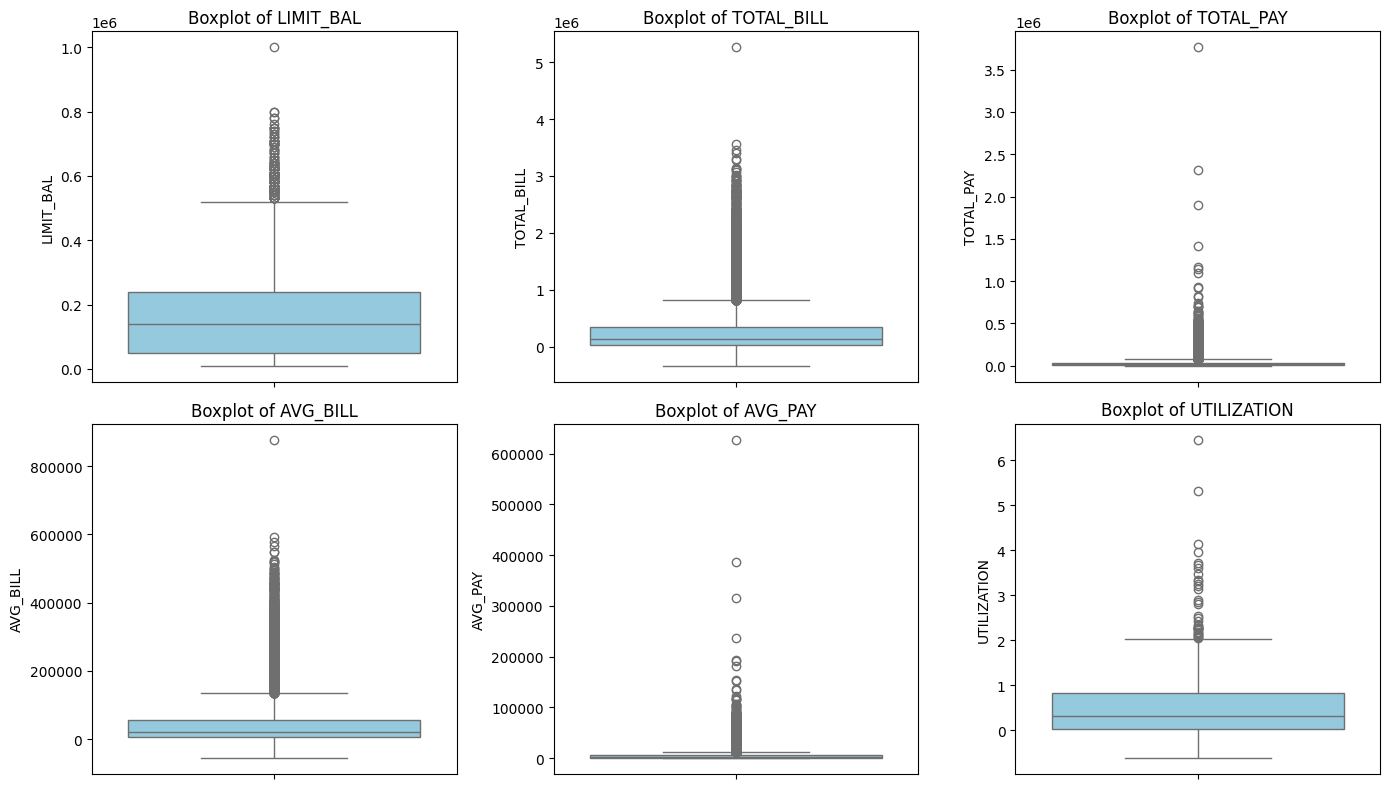

In [ ]:
plt.figure(figsize=(14, 8))
for i, col in enumerate(num_cols[:6], 1):
  plt.subplot(2, 3, i)
  sns.boxplot(y=df[col], color="skyblue")
  plt.title(f"Boxplot of {col}")
  plt.tight_layout()
plt.show()

In [ ]:
#checks IQR Bounds(withou blind deletion)

In [ ]:
# Calculate outlier counts using IQR method
for col in ["LIMIT_BAL", "TOTAL_BILL", "UTILIZATION"]:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  print(
      f"{col}: Found {len(outliers)} statistical outliers (Thresholds: <"
      f" {lower_bound:.2f} or > {upper_bound:.2f})"
  )

LIMIT_BAL: Found 167 statistical outliers (Thresholds: < -235000.00 or > 525000.00)
TOTAL_BILL: Found 2575 statistical outliers (Thresholds: < -442116.75 or > 813501.25)
UTILIZATION: Found 35 statistical outliers (Thresholds: < -1.19 or > 2.04)


In [ ]:
#Investigate High value Customer vs.Defaults

In [ ]:
# Compare default rates for top 1% credit limit customers vs overall dataset
high_limit_threshold = df["LIMIT_BAL"].quantile(0.99)
high_limit_customers = df[df["LIMIT_BAL"] >= high_limit_threshold]

print(f"99th Percentile Limit Threshold: {high_limit_threshold}")
print(
    "Default rate for top 1% limit customers:"
    f" {high_limit_customers['default'].mean():.4f}"
)
print(f"Overall dataset default rate: {df['default'].mean():.4f}")

99th Percentile Limit Threshold: 500000.0
Default rate for top 1% limit customers: 0.1121
Overall dataset default rate: 0.2212


In [ ]:
#Handle skewness with log transformation

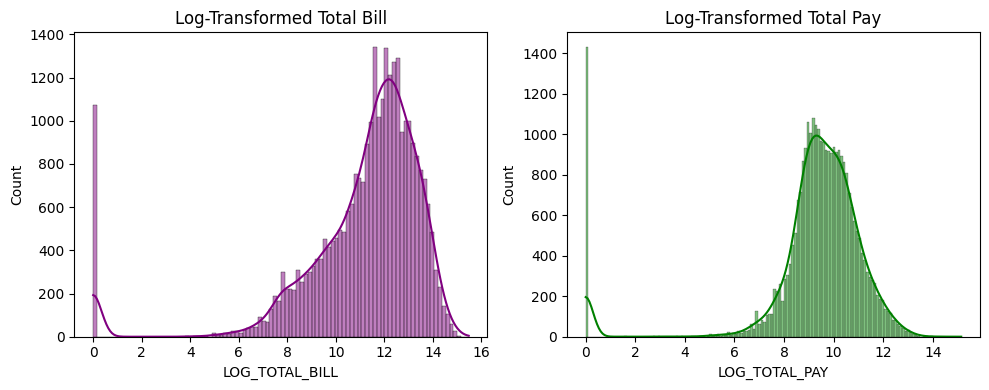

In [ ]:
# Create log-transformed columns safely handling zero or negative values
df["LOG_TOTAL_BILL"] = np.log1p(df["TOTAL_BILL"].clip(lower=0))
df["LOG_TOTAL_PAY"] = np.log1p(df["TOTAL_PAY"].clip(lower=0))

# Visualize log-transformed distributions
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df["LOG_TOTAL_BILL"], kde=True, color="purple")
plt.title("Log-Transformed Total Bill")

plt.subplot(1, 2, 2)
sns.histplot(df["LOG_TOTAL_PAY"], kde=True, color="green")
plt.title("Log-Transformed Total Pay")
plt.tight_layout()
plt.show()

In [ ]:
#Save the updated dataset with outlier analysis features

In [ ]:
df.to_csv("cleaned_with_features.csv", index=False)
print("Outlier analysis features updated. File saved with shape:", df.shape)

Outlier analysis features updated. File saved with shape: (29995, 35)
